In [91]:
import os
import glob
from pathlib import Path
import pandas as pd
import numpy as np
import tensorly as tl
from tensorly.decomposition import parafac
import matplotlib.pyplot as plt
from scipy import stats
from mpl_toolkits.axes_grid1 import make_axes_locatable
import HumSpectra.fluorescence as fl

In [22]:
wdir_2025 = Path.cwd().parent / "initial data" / "2025"
fluo_paths = Path.joinpath(wdir_2025, "Fluorescence")

In [23]:
class EEMDataLoader:
    def __init__(self, data_folder):
        self.data_folder = data_folder
        self.sample_names = []
        self.excitation_wavelengths = None
        self.emission_wavelengths = None
        
    def load_eem_data(self):
        """Загрузка всех EEM спектров из папки"""
        
        # Находим все CSV файлы в папке
        csv_files = glob.glob(os.path.join(self.data_folder, "*.csv"))
        csv_files.sort()  # Сортируем для воспроизводимости
        
        if not csv_files:
            raise ValueError(f"CSV файлы не найдены в папке {self.data_folder}")
        
        eem_matrices = []
        
        for i, file_path in enumerate(csv_files):
            
            # Загружаем CSV файл
            df = fl.read_fluo_3d(file_path,index_col=1)
            df = fl.cut_spectra(df,ex_low_limit=255,ex_high_limit=450,em_low_limit=255,em_high_limit=600)
            
            # Извлекаем длины волн
            if self.excitation_wavelengths is None:
                self.excitation_wavelengths = np.array(df.columns, dtype=float)
            if self.emission_wavelengths is None:
                self.emission_wavelengths = np.array(df.index, dtype=float)
            
            # Преобразуем в numpy array
            eem_matrix = df.values.astype(float)
            eem_matrices.append(eem_matrix)
            
            # Сохраняем имя образца
            self.sample_names.append(os.path.splitext(os.path.basename(file_path))[0])
        
        # Создаем 3D тензор: образцы × испускание × возбуждение
        self.tensor = np.stack(eem_matrices, axis=0)
        
        print(f"Создан тензор размерности: {self.tensor.shape}")
        print(f"Образцы: {len(self.sample_names)}")
        print(f"Длины волн испускания: {len(self.emission_wavelengths)}") # type: ignore
        print(f"Длины волн возбуждения: {len(self.excitation_wavelengths)}") # type: ignore
        
        return tl.tensor(self.tensor),self.emission_wavelengths,self.excitation_wavelengths,self.sample_names
    
    def get_data_info(self):
        """Возвращает информацию о загруженных данных"""
        return {
            'tensor': self.tensor,
            'sample_names': self.sample_names,
            'excitation_wavelengths': self.excitation_wavelengths,
            'emission_wavelengths': self.emission_wavelengths,
            'shape': self.tensor.shape
        }

In [121]:
loader = EEMDataLoader(fluo_paths)
eem_tensor,em_waves,ex_waves,sp_names = loader.load_eem_data()
data_info = loader.get_data_info()

Создан тензор размерности: (108, 70, 40)
Образцы: 108
Длины волн испускания: 70
Длины волн возбуждения: 40


In [142]:
def detect_outliers_parafac(tensor, rank, threshold_std=3.0, max_iter=100, tol=1e-6, verbose=False):
    """
    Обнаружение и исправление выбросов в тензорных данных с помощью PARAFAC.
    Для Tensorly 0.9.0+
    """
    
    # Инициализация
    tensor = tl.tensor(tensor.copy())
    original_shape = tensor.shape
    outlier_mask = np.zeros_like(tensor, dtype=bool)
    
    if verbose:
        print(f"Исходная форма тензора: {original_shape}")
        print(f"Ранг PARAFAC: {rank}")
        print(f"Порог обнаружения: {threshold_std} стандартных отклонений")
    
    # Шаг 1: Первоначальное разложение PARAFAC
    if verbose:
        print("Шаг 1: Первоначальное разложение PARAFAC...")
    
    # В Tensorly 0.9.0 parafac возвращает объект KruskalTensor
    kruskal_result = parafac(
        tensor, 
        rank=rank, 
        n_iter_max=max_iter, 
        tol=tol,
        init='random',
        verbose=verbose
    )
    
    # Шаг 2: Реконструкция тензора - ПРАВИЛЬНЫЙ СПОСОБ для 0.9.0
    reconstructed_tensor = tl.cp_to_tensor(kruskal_result)
    
    # Вычисление невязок
    residuals = tensor - reconstructed_tensor
    residual_flat = residuals.flatten()
    
    # Шаг 3: Обнаружение выбросов по невязкам
    if verbose:
        print("Шаг 2: Обнаружение выбросов...")
    
    # Вычисляем Z-score для невязок
    residual_mean = np.mean(residual_flat)
    residual_std = np.std(residual_flat)
    z_scores = np.abs((residual_flat - residual_mean) / residual_std)
    
    # Создаем маску выбросов
    outlier_threshold = threshold_std
    is_outlier_flat = z_scores > outlier_threshold
    
    # Преобразуем обратно в тензорную форму
    outlier_mask = is_outlier_flat.reshape(original_shape)
    
    # Шаг 4: Создание очищенного тензора
    if verbose:
        print("Шаг 3: Создание очищенного тензора...")
    
    cleaned_tensor = tensor.copy()
    cleaned_tensor[outlier_mask] = reconstructed_tensor[outlier_mask]
    
    # Подсчет статистики
    n_outliers = np.sum(outlier_mask)
    total_elements = np.prod(original_shape)
    outlier_percentage = (n_outliers / total_elements) * 100
    
    if verbose:
        print(f"Обнаружено выбросов: {n_outliers} ({outlier_percentage:.2f}%)")
        print(f"Среднее невязок: {residual_mean:.6f}")
        print(f"Стд. невязок: {residual_std:.6f}")
    
    # Собираем информацию о модели
    model_info = {
        'n_outliers': n_outliers,
        'outlier_percentage': outlier_percentage,
        'residual_mean': residual_mean,
        'residual_std': residual_std,
        'outlier_threshold': outlier_threshold,
        'kruskal_result': kruskal_result
    }
    
    return cleaned_tensor, outlier_mask, residuals, model_info

def alternative_cp_approach(tensor, rank, threshold_std=3.0):
    """
    Альтернативный подход через прямое использование разложения.
    """
    from tensorly.decomposition import non_negative_parafac
    
    # Используем non-negative PARAFAC если обычный не работает
    weights, factors = non_negative_parafac(
        tensor, rank=rank, n_iter_max=100, return_errors=False
    )
    
    # Ручная реконструкция
    reconstructed = np.einsum('ir,jr,kr->ijk', factors[0], factors[1], factors[2])
    
    # Обнаружение выбросов
    residuals = tensor - reconstructed
    residual_std = np.std(residuals)
    
    outlier_mask = np.abs(residuals) > threshold_std * residual_std
    cleaned_tensor = tensor.copy()
    cleaned_tensor[outlier_mask] = reconstructed[outlier_mask]
    
    return cleaned_tensor, outlier_mask, residuals

# Альтернативные способы если основной не работает
def reconstruct_parafac_manual(kruskal_result):
    """
    Ручная реконструкция тензора из KruskalTensor.
    """
    # Получаем факторы из KruskalTensor объекта
    factors = kruskal_result.factors
    weights = kruskal_result.weights
    
    # Реконструкция через einsum
    if weights is not None:
        # Если есть веса, учитываем их
        normalized_factors = []
        for i, factor in enumerate(factors):
            normalized_factors.append(factor * (weights[i] ** (1/len(factors))))
        factors = normalized_factors
    
    # Реконструкция для N-мерного тензора
    pattern = ''.join([chr(97 + i) + 'r,' for i in range(len(factors))])[:-1]
    pattern += '->' + ''.join([chr(97 + i) for i in range(len(factors))])
    
    reconstructed = np.einsum(pattern, *factors)
    return tl.tensor(reconstructed)

def robust_detect_outliers(tensor, rank, threshold_std=3.0, verbose=True):
    """
    Устойчивая версия с несколькими способами реконструкции.
    """
    try:
        tensor = tl.tensor(tensor.copy())
        
        # Выполняем PARAFAC
        kruskal_result = parafac(
            tensor, 
            rank=rank, 
            n_iter_max=100,
            init='random'
        )
        

        reconstructed = reconstruct_parafac_manual(kruskal_result)
        
        # Обнаружение выбросов
        residuals = tensor - reconstructed
        residual_flat = residuals.flatten()
        
        residual_mean = np.mean(residual_flat)
        residual_std = np.std(residual_flat)
        z_scores = np.abs((residual_flat - residual_mean) / residual_std)
        
        outlier_mask = (z_scores > threshold_std).reshape(tensor.shape)
        cleaned_tensor = tensor.copy()
        cleaned_tensor[outlier_mask] = reconstructed[outlier_mask]
        
        n_outliers = np.sum(outlier_mask)
        
        if verbose:
            print(f"Обнаружено выбросов: {n_outliers}")
        
        return cleaned_tensor, outlier_mask, residuals, {
            'n_outliers': n_outliers,
            'residual_mean': residual_mean,
            'residual_std': residual_std,
            'kruskal_result': kruskal_result
        }
        
    except Exception as e:
        print(f"Ошибка при обнаружении выбросов: {e}")
        return tensor, np.zeros_like(tensor, dtype=bool), None, {}

# Проверка доступных методов в текущей версии
def check_available_methods():
    """Проверка доступных методов в установленной версии Tensorly."""
    print(f"Версия Tensorly: {tl.__version__}")
    
    # Проверяем доступные атрибуты в backend
    print("\nДоступные методы в tensorly.backend:")
    backend_methods = [method for method in dir(tl.backend) if not method.startswith('_')]
    for method in sorted(backend_methods):
        print(f"  - {method}")
    
    # Проверяем что возвращает parafac
    print("\nТип результата parafac:")
    test_data = tl.tensor(np.random.random((5, 5, 5)))
    result = parafac(test_data, rank=2, n_iter_max=1)
    print(f"  Тип: {type(result)}")
    print(f"  Атрибуты: {[attr for attr in dir(result) if not attr.startswith('_')]}")
    
    # Проверяем доступность kruskal_to_tensor
    if hasattr(tl, 'kruskal_to_tensor'):
        print("✓ tl.kruskal_to_tensor доступен")
    else:
        print("✗ tl.kruskal_to_tensor недоступен")
    
    # Проверяем другие возможные места
    for module in ['kruskal_tensor', 'tenalg']:
        try:
            mod = __import__(f'tensorly.{module}', fromlist=[''])
            if hasattr(mod, 'kruskal_to_tensor'):
                print(f"✓ tensorly.{module}.kruskal_to_tensor доступен")
        except ImportError:
            pass
        
def create_test_data():
    """Создание тестовых данных с известными выбросами."""
    np.random.seed(42)
    
    # Создаем базовый тензор с некоторой структурой
    base_tensor = np.random.normal(0, 1, (15, 12, 8))
    
    # Добавляем структуру через внешнее произведение
    A = np.random.normal(0, 1, (15, 3))
    B = np.random.normal(0, 1, (12, 3)) 
    C = np.random.normal(0, 1, (8, 3))
    
    structured = np.einsum('ir,jr,kr->ijk', A, B, C)
    tensor = base_tensor + 0.5 * structured
    
    # Добавляем выбросы
    outliers = [
        (5, 5, 5, 10.0),   # (i, j, k, значение)
        (10, 3, 2, -8.0),
        (3, 8, 6, 12.0),
        (12, 10, 4, -9.0)
    ]
    
    outlier_positions = []
    for i, j, k, val in outliers:
        tensor[i, j, k] = val
        outlier_positions.append((i, j, k))
    
    return tl.tensor(tensor), outlier_positions

def test_algorithm():
    """Тестирование алгоритма на синтетических данных."""
    print("=== ТЕСТИРОВАНИЕ АЛГОРИТМА ОБНАРУЖЕНИЯ ВЫБРОСОВ ===\n")
    
    # Проверяем доступные методы
    check_available_methods()
    
    print("\n" + "="*50)
    print("Создание тестовых данных...")
    
    # Создаем данные с известными выбросами
    test_tensor, true_outliers = create_test_data()
    print(f"Создан тензор размерности: {test_tensor.shape}")
    print(f"Добавлено {len(true_outliers)} известных выбросов")
    
    print("\nЗапуск обнаружения выбросов...")
    
    # Запускаем алгоритм
    cleaned, mask, residuals, info = robust_detect_outliers(
        test_tensor, rank=3, threshold_std=3.0, verbose=True
    )
    
    # Проверяем результаты
    print(f"\n=== РЕЗУЛЬТАТЫ ===")
    print(f"Обнаружено выбросов: {info['n_outliers']}")
    print(f"Процент выбросов: {info['n_outliers'] / test_tensor.size * 100:.2f}%")
    
    # Проверяем, нашли ли мы известные выбросы
    detected_true = 0
    for pos in true_outliers:
        if mask[pos]:
            detected_true += 1
    
    print(f"Обнаружено известных выбросов: {detected_true}/{len(true_outliers)}")
    
    if detected_true == len(true_outliers):
        print("✓ Все известные выбросы обнаружены!")
    else:
        print("✗ Не все выбросы обнаружены")
    
    return cleaned, mask, info, true_outliers


In [122]:
cleaned, mask, residuals, info = robust_detect_outliers(
        eem_tensor, rank=4, threshold_std=3.0, verbose=True
    )

Обнаружено выбросов: 7038


In [69]:
print(f"Процент выбросов: {info['n_outliers'] / eem_tensor.size * 100:.2f}%")
print(f"Обнаружено выбросов: {info['n_outliers']}")

Процент выбросов: 2.35%
Обнаружено выбросов: 7108


In [90]:
class ComponentVisualizer:
    def __init__(self, analyzer):
        self.analyzer = analyzer
    
    def plot_single_component_eem(self, component_idx, sample_idx=None, 
                                normalization='max', figsize=(12, 8)):
        """
        Построение EEM спектра для одного компонента
        
        Args:
            component_idx: индекс компонента (0-based)
            sample_idx: индекс образца для масштабирования (если None - используется максимальная нагрузка)
            normalization: метод нормализации ('max', 'none')
        """
        if not hasattr(self.analyzer, 'parafac_result'):
            raise ValueError("Сначала выполните PARAFAC анализ")
        
        # Получаем факторы
        factors = self.analyzer.factors
        weights = self.analyzer.weights
        
        # Индексы для модов: 0-образцы, 1-испускание, 2-возбуждение
        sample_factor = factors[0]  # Нагрузки образцов
        emission_factor = factors[1]  # Спектр испускания
        excitation_factor = factors[2]  # Спектр возбуждения
        
        # Создаем EEM матрицу для компонента
        component_eem = np.outer(emission_factor[:, component_idx], 
                               excitation_factor[:, component_idx])
        
        # Масштабируем с учетом весов и нагрузок образца
        if weights is not None:
            scale_factor = weights[component_idx]
        else:
            scale_factor = 1.0
        
        if sample_idx is not None:
            # Масштабируем по конкретному образцу
            sample_loading = sample_factor[sample_idx, component_idx]
            component_eem = component_eem * scale_factor * sample_loading
        else:
            # Используем максимальную нагрузку для масштабирования
            max_loading = np.max(sample_factor[:, component_idx])
            component_eem = component_eem * scale_factor * max_loading
        
        # Нормализация
        if normalization == 'max':
            component_eem = component_eem / np.max(component_eem)
        
        # Создаем график
        fig, ax = plt.subplots(figsize=figsize)
        
        # Контурный график
        X, Y = np.meshgrid(self.analyzer.excitation_wavelengths, 
                          self.analyzer.emission_wavelengths)
        
        # Уровни для контурных линий
        levels = np.linspace(np.min(component_eem), np.max(component_eem), 20)
        
        # Контурный график
        contour = ax.contour(X, Y, component_eem, levels=levels, colors='black', linewidths=0.5)
        ax.clabel(contour, inline=True, fontsize=8, fmt='%.2f')
        
        # Heatmap
        im = ax.contourf(X, Y, component_eem, levels=50, cmap='viridis')
        
        # Настройки осей
        ax.set_xlabel('Длина волны возбуждения, нм')
        ax.set_ylabel('Длина волны испускания, нм')
        
        sample_info = ""
        if sample_idx is not None:
            if self.analyzer.sample_names:
                sample_info = f" (масштабировано для {self.analyzer.sample_names[sample_idx]})"
            else:
                sample_info = f" (масштабировано для образца {sample_idx})"
        
        ax.set_title(f'EEM спектр компонента {component_idx+1}{sample_info}\n'
                    f'Нормализация: {normalization}')
        
        # Цветовая шкала
        divider = make_axes_locatable(ax)
        cax = divider.append_axes("right", size="5%", pad=0.1)
        plt.colorbar(im, cax=cax, label='Интенсивность (норм.)')
        
        plt.tight_layout()
        return fig, ax, component_eem
    
    def plot_component_spectra(self, component_idx, figsize=(12, 6)):
        """Построение отдельных спектров возбуждения и испускания"""
        factors = self.analyzer.factors
        
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=figsize)
        
        # Спектр испускания
        emission_spectrum = factors[1][:, component_idx]
        ax1.plot(self.analyzer.emission_wavelengths, emission_spectrum, 
                'b-', linewidth=2, label=f'Компонент {component_idx+1}')
        ax1.set_xlabel('Длина волны испускания, нм')
        ax1.set_ylabel('Интенсивность (норм.)')
        ax1.set_title('Спектр испускания')
        ax1.legend()
        ax1.grid(True, alpha=0.3)
        
        # Спектр возбуждения
        excitation_spectrum = factors[2][:, component_idx]
        ax2.plot(self.analyzer.excitation_wavelengths, excitation_spectrum,
                'r-', linewidth=2, label=f'Компонент {component_idx+1}')
        ax2.set_xlabel('Длина волны возбуждения, нм')
        ax2.set_ylabel('Интенсивность (норм.)')
        ax2.set_title('Спектр возбуждения')
        ax2.legend()
        ax2.grid(True, alpha=0.3)
        
        plt.tight_layout()
        return fig

In [172]:
class OpticalDataAnalyzer:
    def __init__(self, n_components=3):
        self.n_components = n_components
        
    def fit_parafac(self, X, excitation_wavelengths=None, emission_wavelengths=None, sample_names=None, 
                    non_negative=True, init='svd', n_iter_max=2000, tol=1e-8):
        """
        PARAFAC разложение с реальными длинами волн
        
        Args:
            X: 3D тензор (образцы × испускание × возбуждение)
            excitation_wavelengths: массив длин волн возбуждения
            emission_wavelengths: массив длин волн испускания
            sample_names: список имен образцов
            non_negative: использовать неотрицательный PARAFAC (рекомендуется для DOM)
            init: метод инициализации ('svd', 'random')
            n_iter_max: максимальное количество итераций
            tol: точность сходимости
        """
        self.excitation_wavelengths = excitation_wavelengths
        self.emission_wavelengths = emission_wavelengths
        self.sample_names = sample_names
        self.X = X
        self.non_negative = non_negative
        
        # Предобработка данных для DOM анализа
        X_processed = self._preprocess_data(X)
        
        # PARAFAC разложение
        if non_negative:
            # Неотрицательный PARAFAC для DOM анализа
            from tensorly.decomposition import non_negative_parafac
            
            self.parafac_result = non_negative_parafac(
                X_processed, 
                rank=self.n_components,
                init=init,
                tol=tol,
                n_iter_max=n_iter_max,
                verbose=1,  # Вывод прогресса
                return_errors=True
            )
            
            # Для non_negative_parafac в новых версиях Tensorly

            # Другие возможные форматы
            self.factors = self.parafac_result
            self.weights = None
                
        else:
            # Обычный PARAFAC (не рекомендуется для DOM)
            self.parafac_result = parafac(
                X_processed, 
                rank=self.n_components,
                init=init,
                tol=tol,
                n_iter_max=n_iter_max
            )
            
            # Извлекаем факторы в зависимости от типа результата
            if hasattr(self.parafac_result, 'factors'):
                self.weights = self.parafac_result.weights
                self.factors = self.parafac_result.factors
            else:
                self.weights, self.factors = self.parafac_result
        
        # Валидация результатов
        self._validate_results()
        
        
        # Дополнительная информация о разложении
        self._calculate_additional_metrics(X_processed)
            
        
        return self.factors

    def _preprocess_data(self, X):
        """
        Предобработка данных для DOM анализа
        """
        X_processed = X.copy()
        
        # 1. Убедиться в неотрицательности данных
        if np.any(X_processed < 0):
            print("⚠️ Обнаружены отрицательные значения. Заменяем на 0.")
            X_processed = np.maximum(X_processed, 0)
        
        # 2. Нормализация данных (опционально)
        if self.non_negative:
            # Для неотрицательного PARAFAC можно использовать нормализацию
            max_val = np.max(X_processed)
            if max_val > 1:
                print(f"Масштабирование данных: максимальное значение = {max_val}")
                X_processed = X_processed / max_val
        
        return X_processed

    def _validate_results(self):
        """
        Валидация результатов PARAFAC разложения
        """
        print("\n=== ВАЛИДАЦИЯ РЕЗУЛЬТАТОВ ===")
        
        # Проверка неотрицательности
        if self.non_negative:
            tolerance = 1e-10
            for i, factor in enumerate(self.factors):
                min_val = np.min(factor)
                if min_val < -tolerance:
                    print(f"❌ Фактор {i} содержит отрицательные значения: min = {min_val:.2e}")
                else:
                    print(f"✅ Фактор {i}: неотрицательный (min = {min_val:.2e})")
        
        # Проверка сходимости
        if hasattr(self.parafac_result, 'errors'):
            errors = self.parafac_result.errors
            if len(errors) > 1:
                final_error = errors[-1]
                prev_error = errors[-2] if len(errors) > 1 else errors[-1]
                convergence = abs(final_error - prev_error) / prev_error
                print(f"Ошибка реконструкции: {final_error:.2e}")
                print(f"Сходимость: {convergence:.2e}")
        
        # Информация о факторах
        for i, factor in enumerate(self.factors):
            print(f"Фактор {i}: форма {factor.shape}, диапазон [{np.min(factor):.3f}, {np.max(factor):.3f}]")

    def _calculate_additional_metrics(self, X):
        """
        Расчет дополнительных метрик качества разложения
        """
        try:
            # Реконструкция тензора
            reconstructed = tl.cp_to_tensor(self.parafac_result)
            
            # Объясненная дисперсия
            ss_total = np.sum(X ** 2)
            ss_residual = np.sum((X - reconstructed) ** 2)
            explained_variance = (1 - ss_residual / ss_total) * 100
            
            print(f"\n=== МЕТРИКИ КАЧЕСТВА ===")
            print(f"Объясненная дисперсия: {explained_variance:.2f}%")
            
            # Core Consistency (опционально)
            core_consistency = self._calculate_core_consistency(X, reconstructed)
            if core_consistency is not None:
                print(f"Core Consistency: {core_consistency:.2f}%")
            
            self.explained_variance = explained_variance
            
        except Exception as e:
            print(f"Не удалось рассчитать дополнительные метрики: {e}")

    def _calculate_core_consistency(self, X, reconstructed):
        """
        Расчет Core Consistency для проверки модели
        """
        try:
            # Упрощенная версия расчета core consistency
            correlation = np.corrcoef(X.flatten(), reconstructed.flatten())[0, 1]
            return correlation * 100
        except:
            return None

    # Добавляем метод для выбора оптимального числа компонентов
    def find_optimal_components(self, X, max_components=6, **kwargs):
        """
        Поиск оптимального числа компонентов через анализ отсечки
        """
        from math import log10
        
        print("=== ПОИСК ОПТИМАЛЬНОГО ЧИСЛА КОМПОНЕНТОВ ===")
        
        explained_variances = []
        core_consistencies = []
        
        for n_comp in range(1, max_components + 1):
            print(f"\nТестирование {n_comp} компонентов...")
            
            # Временно меняем число компонентов
            original_components = self.n_components
            self.n_components = n_comp
            
            # Выполняем разложение
            self.fit_parafac(X, **kwargs)
            
            explained_variances.append(self.explained_variance)
            
            print(f"Объясненная дисперсия для {n_comp} компонентов: {self.explained_variance:.2f}%")
            
            print(f"Ошибка для {n_comp} компонентов: {e}")
            explained_variances.append(0)
            self.n_components = original_components
        
        # Анализ "локтя" на графике
        self._plot_scree(explained_variances)
        
        return explained_variances

    def _plot_scree(self, explained_variances):
        """
        Построение графика отсечки для выбора числа компонентов
        """
        plt.figure(figsize=(10, 6))
        n_components = range(1, len(explained_variances) + 1)
        
        plt.plot(n_components, explained_variances, 'bo-', linewidth=2, markersize=8)
        plt.xlabel('Число компонентов')
        plt.ylabel('Объясненная дисперсия, %')
        plt.title('График отсечки для выбора числа компонентов')
        plt.grid(True, alpha=0.3)
        
        # Добавление разностей
        differences = [0] + [explained_variances[i] - explained_variances[i-1] 
                            for i in range(1, len(explained_variances))]
        
        plt.twinx()
        plt.plot(n_components, differences, 'ro--', linewidth=1, markersize=6, alpha=0.7)
        plt.ylabel('Прирост дисперсии, %', color='red')
        
        plt.tight_layout()
        plt.show()
    
    def plot_component_profiles(self, figsize=(15, 10)):
        """
        Визуализация компонентов с реальными длинами волн
        """
        if not hasattr(self, 'factors'):
            raise ValueError("Сначала выполните fit_parafac()")
        
        fig, axes = plt.subplots(2, self.n_components, figsize=figsize)
        
        for i in range(self.n_components):
            # Спектры возбуждения
            if self.excitation_wavelengths is not None:
                x_exc = self.excitation_wavelengths
                xlabel_exc = 'Длина волны возбуждения (нм)'
            else:
                x_exc = np.arange(len(self.factors[2][:, i]))
                xlabel_exc = 'Индекс длины волны возбуждения'
            
            axes[0, i].plot(x_exc, self.factors[2][:, i], 'b-', linewidth=2)
            axes[0, i].set_title(f'Компонент {i+1} - Возбуждение')
            axes[0, i].set_xlabel(xlabel_exc)
            axes[0, i].set_ylabel('Интенсивность')
            axes[0, i].grid(True, alpha=0.3)
            
            # Находим и отмечаем максимум
            max_idx = np.argmax(self.factors[2][:, i])
            max_val = self.factors[2][max_idx, i]
            if self.excitation_wavelengths is not None:
                max_wavelength = self.excitation_wavelengths[max_idx]
                axes[0, i].axvline(x=max_wavelength, color='red', linestyle='--', alpha=0.7)
                axes[0, i].text(0.05, 0.95, f'λ_max = {max_wavelength:.1f} нм', 
                               transform=axes[0, i].transAxes, verticalalignment='top',
                               bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
            
            # Спектры испускания
            if self.emission_wavelengths is not None:
                x_em = self.emission_wavelengths
                xlabel_em = 'Длина волны испускания (нм)'
            else:
                x_em = np.arange(len(self.factors[1][:, i]))
                xlabel_em = 'Индекс длины волны испускания'
            
            axes[1, i].plot(x_em, self.factors[1][:, i], 'r-', linewidth=2)
            axes[1, i].set_title(f'Компонент {i+1} - Испускание')
            axes[1, i].set_xlabel(xlabel_em)
            axes[1, i].set_ylabel('Интенсивность')
            axes[1, i].grid(True, alpha=0.3)
            
            # Находим и отмечаем максимум
            max_idx_em = np.argmax(self.factors[1][:, i])
            max_val_em = self.factors[1][max_idx_em, i]
            if self.emission_wavelengths is not None:
                max_wavelength_em = self.emission_wavelengths[max_idx_em]
                axes[1, i].axvline(x=max_wavelength_em, color='red', linestyle='--', alpha=0.7)
                axes[1, i].text(0.05, 0.95, f'λ_max = {max_wavelength_em:.1f} нм', 
                               transform=axes[1, i].transAxes, verticalalignment='top',
                               bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
        
        plt.tight_layout()
        plt.show()
    
    def plot_concentration_profiles(self, figsize=(12, 6)):
        """
        Визуализация концентраций с именами образцов
        """
        if not hasattr(self, 'factors'):
            raise ValueError("Сначала выполните fit_parafac()")
        
        concentrations = self.factors[0]
        
        plt.figure(figsize=figsize)
        
        # Создаем ось X
        if self.sample_names is not None:
            x_pos = np.arange(len(self.sample_names))
            plt.xticks(x_pos, self.sample_names, rotation=45, ha='right')
        else:
            x_pos = np.arange(concentrations.shape[0])
        
        # Рисуем концентрации для каждого компонента
        for i in range(self.n_components):
            plt.plot(x_pos, concentrations[:, i], 'o-', linewidth=2, 
                    markersize=6, label=f'Компонент {i+1}')
        
        plt.xlabel('Образцы')
        plt.ylabel('Относительная концентрация')
        plt.title('Распределение компонентов по образцам')
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()
    
    def plot_eem_contours(self, sample_idx=0, n_levels=20, figsize=(10, 8)):
        """
        Контурный график EEM для выбранного образца
        """
        if not hasattr(self, 'factors'):
            raise ValueError("Сначала выполните fit_parafac()")
        
        # Реконструируем EEM для выбранного образца
        sample_eem = self.reconstruct_sample(sample_idx)
        
        plt.figure(figsize=figsize)
        
        # Контурный график
        if self.excitation_wavelengths is not None and self.emission_wavelengths is not None:
            X, Y = np.meshgrid(self.excitation_wavelengths, self.emission_wavelengths)
            contour = plt.contourf(X, Y, sample_eem, levels=n_levels, cmap='viridis')
            plt.colorbar(contour, label='Интенсивность флуоресценции')
            plt.xlabel('Длина волны возбуждения (нм)')
            plt.ylabel('Длина волны испускания (нм)')
            
            sample_name = self.sample_names[sample_idx] if self.sample_names else f"Образец {sample_idx+1}"
            plt.title(f'Контурный график EEM: {sample_name}')
        else:
            plt.imshow(sample_eem, aspect='auto', cmap='viridis')
            plt.colorbar(label='Интенсивность флуоресценции')
            plt.xlabel('Индекс возбуждения')
            plt.ylabel('Индекс испускания')
            plt.title(f'EEM матрица: Образец {sample_idx+1}')
        
        plt.tight_layout()
        plt.show()
    
    def reconstruct_sample(self, sample_idx):
        """Реконструкция EEM для конкретного образца"""
        reconstructed = np.zeros((len(self.emission_wavelengths),  # pyright: ignore[reportArgumentType]
                                len(self.excitation_wavelengths))) # type: ignore
        
        for r in range(self.n_components):
            concentration = self.factors[0][sample_idx, r]
            excitation_profile = self.factors[2][:, r]
            emission_profile = self.factors[1][:, r]
            
            outer_product = np.outer(emission_profile, excitation_profile)
            reconstructed += concentration * outer_product
        
        return reconstructed
    
    def get_component_maxima(self):
        """
        Возвращает максимумы возбуждения и испускания для каждого компонента
        """
        maxima = []
        
        for i in range(self.n_components):
            # Максимум возбуждения
            exc_max_idx = np.argmax(self.factors[2][:, i])
            exc_max_wavelength = self.excitation_wavelengths[exc_max_idx] if self.excitation_wavelengths is not None else exc_max_idx
            exc_max_intensity = self.factors[2][exc_max_idx, i]
            
            # Максимум испускания
            em_max_idx = np.argmax(self.factors[1][:, i])
            em_max_wavelength = self.emission_wavelengths[em_max_idx] if self.emission_wavelengths is not None else em_max_idx
            em_max_intensity = self.factors[1][em_max_idx, i]
            
            maxima.append({
                'component': i + 1,
                'excitation_max': exc_max_wavelength,
                'excitation_intensity': exc_max_intensity,
                'emission_max': em_max_wavelength,
                'emission_intensity': em_max_intensity
            })
        
        return maxima
    
    def print_component_summary(self):
        """Печатает сводку по компонентам"""
        maxima = self.get_component_maxima()
        
        print("=" * 60)
        print("СВОДКА ПО КОМПОНЕНТАМ PARAFAC")
        print("=" * 60)
        
        for comp in maxima:
            print(f"Компонент {comp['component']}:")
            print(f"  Возбуждение: λ_max = {comp['excitation_max']:.1f} нм")
            print(f"  Испускание: λ_max = {comp['emission_max']:.1f} нм")
            print(f"  Stokes shift: {comp['emission_max'] - comp['excitation_max']:.1f} нм")
            print()
            
    def get_component_loadings(self, normalization='max'):
        """
        Получить таблицу с долями компонентов для каждого образца
        
        Args:
            normalization: метод нормализации
                - 'max': нормализация по максимуму (0-1)
                - 'sum': нормализация к сумме = 1 (доли)
                - 'none': без нормализации
                - 'zscore': z-score нормализация
        
        Returns:
            pandas.DataFrame: таблица с долями компонентов
        """
        if not hasattr(self, 'factors'):
            raise ValueError("Сначала выполните fit_parafac()")
        
        # Фактор для образцов (предполагаем, что это первый мод)
        sample_factor = self.factors[0]
        
        # Создаем DataFrame
        if self.sample_names is not None:
            index = self.sample_names
        else:
            index = [f"Sample_{i+1}" for i in range(sample_factor.shape[0])]
        
        columns = [f"Component_{i+1}" for i in range(self.n_components)]
        
        loadings_df = pd.DataFrame(sample_factor, index=index, columns=columns)
        
        # Применяем нормализацию
        if normalization == 'max':
            # Нормализация по максимуму в каждом компоненте
            loadings_df = loadings_df / loadings_df.abs().max()
        elif normalization == 'sum':
            # Нормализация к сумме = 1 (доли)
            loadings_df = loadings_df.div(loadings_df.sum(axis=1), axis=0)
        elif normalization == 'row_sum':
            # Нормализация по строкам (сумма по образцу = 1)
            loadings_df = loadings_df.div(loadings_df.sum(axis=1), axis=0)
        elif normalization == 'zscore':
            # Z-score нормализация
            loadings_df = (loadings_df - loadings_df.mean()) / loadings_df.std()
        elif normalization == 'percentage':
            loadings_df = loadings_df.abs().div(loadings_df.abs().sum(axis=1), axis=0) * 100
        elif normalization == 'none':
            # Без нормализации
            pass
        else:
            raise ValueError(f"Неизвестный метод нормализации: {normalization}")
        
        return loadings_df
    
    def get_relative_contributions(self, method='absolute'):
        """
        Получить относительные вклады компонентов
        
        Args:
            method: метод расчета вкладов
                - 'absolute': абсолютные значения нагрузок
                - 'percentage': проценты от общей суммы
                - 'variance': вклад в объясненную дисперсию
        
        Returns:
            pandas.DataFrame: таблица с относительными вкладами
        """
        loadings_df = self.get_component_loadings(normalization='none')
        
        if method == 'absolute':
            return loadings_df
            
        elif method == 'percentage':
            # Процентный вклад каждого компонента в каждом образце
            percentages = loadings_df.abs().div(loadings_df.abs().sum(axis=1), axis=0) * 100
            return percentages.round(4)
            
        elif method == 'variance':
            # Оценка вклада в объясненную дисперсию
            explained_variance = self.calculate_explained_variance()
            variance_contributions = {}
            
            for i, comp in enumerate(loadings_df.columns):
                # Взвешиваем нагрузку на долю объясненной дисперсии компонента
                variance_contributions[comp] = (loadings_df[comp].abs() * 
                                              explained_variance[i]).values
            
            result_df = pd.DataFrame(variance_contributions, index=loadings_df.index)
            return result_df.div(result_df.sum(axis=1), axis=0) * 100
            
        else:
            raise ValueError(f"Неизвестный метод: {method}")
    
    def calculate_explained_variance(self):
        """
        Рассчитать объясненную дисперсию для каждого компонента
        """
        
        # Реконструируем тензор
        reconstructed = tl.cp_to_tensor(self.parafac_result)
        
        # Общая сумма квадратов
        total_ss = np.sum(self.X ** 2)
        
        # Объясненная сумма квадратов
        explained_ss = np.sum(reconstructed ** 2)
        
        # Вклад каждого компонента
        component_variances = []
        for i in range(self.n_components):
            # Создаем тензор только для i-го компонента
            component_factors = []
            for factor in self.factors:
                component_factor = np.zeros_like(factor)
                component_factor[:, i:i+1] = factor[:, i:i+1]
                component_factors.append(component_factor)
            
            if self.weights is not None:
                component_weights = np.zeros_like(self.weights)
                component_weights[i] = self.weights[i]
                component_tensor = tl.cp_to_tensor((component_weights, component_factors))
            else:
                component_tensor = tl.cp_to_tensor(component_factors)
            
            component_ss = np.sum(component_tensor ** 2)
            component_variances.append(component_ss / total_ss * 100)
        
        return component_variances
    
    def get_component_summary(self):
        """
        Получить сводную таблицу по компонентам
        """
        # Доли образцов
        sample_loadings = self.get_component_loadings(normalization='none')
        
        # Процентные вклады
        percentages = self.get_relative_contributions(method='percentage')
        
        # Объясненная дисперсия
        explained_var = self.calculate_explained_variance()
        
        summary_data = {}
        for i in range(self.n_components):
            comp_name = f"Component_{i+1}"
            summary_data[comp_name] = {
                'Max_Loading': sample_loadings[comp_name].max(),
                'Min_Loading': sample_loadings[comp_name].min(),
                'Mean_Loading': sample_loadings[comp_name].mean(),
                'Std_Loading': sample_loadings[comp_name].std(),
                'Max_Percentage': percentages[comp_name].max(),
                'Mean_Percentage': percentages[comp_name].mean(),
                'Explained_Variance_%': explained_var[i]
            }
        
        return pd.DataFrame(summary_data).T
    
    def get_sample_composition(self, sample_index=None, sample_name=None, top_components=None):
        """
        Получить состав конкретного образца по компонентам
        
        Args:
            sample_index: индекс образца
            sample_name: имя образца
            top_components: количество главных компонентов для отображения
        
        Returns:
            pandas.Series: состав образца
        """
        if sample_name is not None and self.sample_names is not None:
            if sample_name not in self.sample_names:
                raise ValueError(f"Образец {sample_name} не найден")
            sample_index = self.sample_names.index(sample_name)
        
        if sample_index is None:
            raise ValueError("Укажите sample_index или sample_name")
        
        percentages = self.get_relative_contributions(method='percentage')
        sample_data = percentages.iloc[sample_index]
        
        if top_components is not None:
            sample_data = sample_data.nlargest(top_components)
        
        return sample_data.round(2)
    
    def export_loadings_to_csv(self, filename, normalization='percentage'):
        """
        Экспорт таблицы нагрузок в CSV файл
        
        Args:
            filename: имя файла
            normalization: метод нормализации
        """
        if normalization == 'percentage':
            df = self.get_relative_contributions(method='percentage')
        else:
            df = self.get_component_loadings(normalization=normalization)
        
        df.to_csv(filename)
        print(f"Таблица сохранена в {filename}")
    
    def plot_component_loadings(self, normalization='max', figsize=(12, 6)):
        """
        Визуализация нагрузок компонентов
        """
        import matplotlib.pyplot as plt
        import seaborn as sns
        
        loadings_df = self.get_component_loadings(normalization=normalization)
        
        plt.figure(figsize=figsize)
        
        if normalization == 'percentage':
            # Столбчатая диаграмма для процентных вкладов
            loadings_df.plot(kind='bar', stacked=True)
            plt.ylabel('Доля компонента, %')
            plt.title('Относительные вклады компонентов в образцы')
        else:
            # Heatmap для обычных нагрузок
            sns.heatmap(loadings_df, annot=False, cmap='RdBu_r', center=0,
                       fmt='.3f', linewidths=0.5)
            plt.title('Нагрузки компонентов по образцам')
        
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()
        
    def plot_component_eem(self, component_idx, sample_idx=None, 
                          normalization='max', figsize=(12, 8)):
        """Построение EEM спектра для компонента"""
        visualizer = ComponentVisualizer(self)
        return visualizer.plot_single_component_eem(
            component_idx, sample_idx, normalization, figsize
        )
    
    def get_component_eem_matrix(self, component_idx, sample_idx=None):
        """Получить EEM матрицу для компонента"""
        factors = self.factors
        emission = factors[1][:, component_idx]
        excitation = factors[2][:, component_idx]
        
        component_eem = np.outer(emission, excitation)
        
        if sample_idx is not None:
            sample_loading = factors[0][sample_idx, component_idx]
            component_eem = component_eem * sample_loading
        
        return component_eem
    
    def plot_all_components_eem(self):
        """Построение EEM для всех компонентов"""
        fig, axes = plt.subplots(self.n_components, 1, figsize=(10, 16))
        
        if self.n_components == 1:
            axes = [axes]
        
        for i in range(self.n_components):
            component_eem = self.get_component_eem_matrix(i)
            component_eem = component_eem / np.max(component_eem)
            
            X, Y = np.meshgrid(self.excitation_wavelengths, 
                              self.emission_wavelengths)
            
            im = axes[i].contourf(X, Y, component_eem, levels=50, cmap='viridis')
            axes[i].contour(X, Y, component_eem, levels=10, colors='black', linewidths=0.3)
            
            axes[i].set_title(f'Component {i+1}')
            axes[i].set_xlabel('Excitation (nm)')
            axes[i].set_ylabel('Emission (nm)')
            
            plt.colorbar(im, ax=axes[i])
        
        plt.tight_layout()
        return fig

In [173]:
analyzer = OpticalDataAnalyzer(n_components=4)

In [174]:
# 1. Автоматический подбор числа компонентов
variances = analyzer.find_optimal_components(
    cleaned, 
    max_components=6,
    excitation_wavelengths=ex_waves,
    emission_wavelengths=em_waves,
    sample_names=sp_names,
    non_negative=True,  # Всегда True для DOM!
    init='svd',         # Лучшая инициализация для спектроскопии
    n_iter_max=2000,    # Больше итераций для сходимости
    tol=1e-8            # Высокая точность
)

=== ПОИСК ОПТИМАЛЬНОГО ЧИСЛА КОМПОНЕНТОВ ===

Тестирование 1 компонентов...
⚠️ Обнаружены отрицательные значения. Заменяем на 0.
Масштабирование данных: максимальное значение = 25.4748288587768
reconstruction error=0.19529702647490255
iteration 1, reconstraction error: 0.1952969230265945, decrease = 1.0344830805864014e-07
iteration 2, reconstraction error: 0.19529692247179314, decrease = 5.548013437550736e-10
PARAFAC converged after 2 iterations

=== ВАЛИДАЦИЯ РЕЗУЛЬТАТОВ ===


ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (2,) + inhomogeneous part.

In [152]:
analyzer.n_components = 3  # Оптимальное число из анализа
factors = analyzer.fit_parafac(
    cleaned,
    excitation_wavelengths=ex_waves,
    emission_wavelengths=em_waves,
    sample_names=sp_names,
    non_negative=True
)

⚠️ Обнаружены отрицательные значения. Заменяем на 0.
Масштабирование данных: максимальное значение = 25.4748288587768
reconstruction error=0.19520764128287008
iteration 1, reconstraction error: 0.19493791854639433, decrease = 0.0002697227364757415
iteration 2, reconstraction error: 0.19430781905487618, decrease = 0.0006300994915181546
iteration 3, reconstraction error: 0.19321612380713488, decrease = 0.0010916952477413033
iteration 4, reconstraction error: 0.19173052361789597, decrease = 0.001485600189238906
iteration 5, reconstraction error: 0.18988552047073629, decrease = 0.001845003147159685
iteration 6, reconstraction error: 0.1878866651744849, decrease = 0.0019988552962513784
iteration 7, reconstraction error: 0.18542315885400176, decrease = 0.0024635063204831442
iteration 8, reconstraction error: 0.18198140306616997, decrease = 0.0034417557878317906
iteration 9, reconstraction error: 0.178354463248801, decrease = 0.0036269398173689738
iteration 10, reconstraction error: 0.1752172

⚠️ Обнаружены отрицательные значения. Заменяем на 0.
Масштабирование данных: максимальное значение = 25.4748288587768
reconstruction error=0.19513882014664846
iteration 1, reconstraction error: 0.19464652338946972, decrease = 0.0004922967571787396
iteration 2, reconstraction error: 0.19361106344628448, decrease = 0.0010354599431852407
iteration 3, reconstraction error: 0.19224733012519457, decrease = 0.0013637333210899105
iteration 4, reconstraction error: 0.19038656770921664, decrease = 0.0018607624159779346
iteration 5, reconstraction error: 0.18786183413136248, decrease = 0.0025247335778541546
iteration 6, reconstraction error: 0.18466181365290632, decrease = 0.0032000204784561614
iteration 7, reconstraction error: 0.18042127590877696, decrease = 0.004240537744129358
iteration 8, reconstraction error: 0.17569981020865655, decrease = 0.004721465700120414
iteration 9, reconstraction error: 0.17058862658521348, decrease = 0.005111183623443066
iteration 10, reconstraction error: 0.16454

IndexError: invalid index to scalar variable.

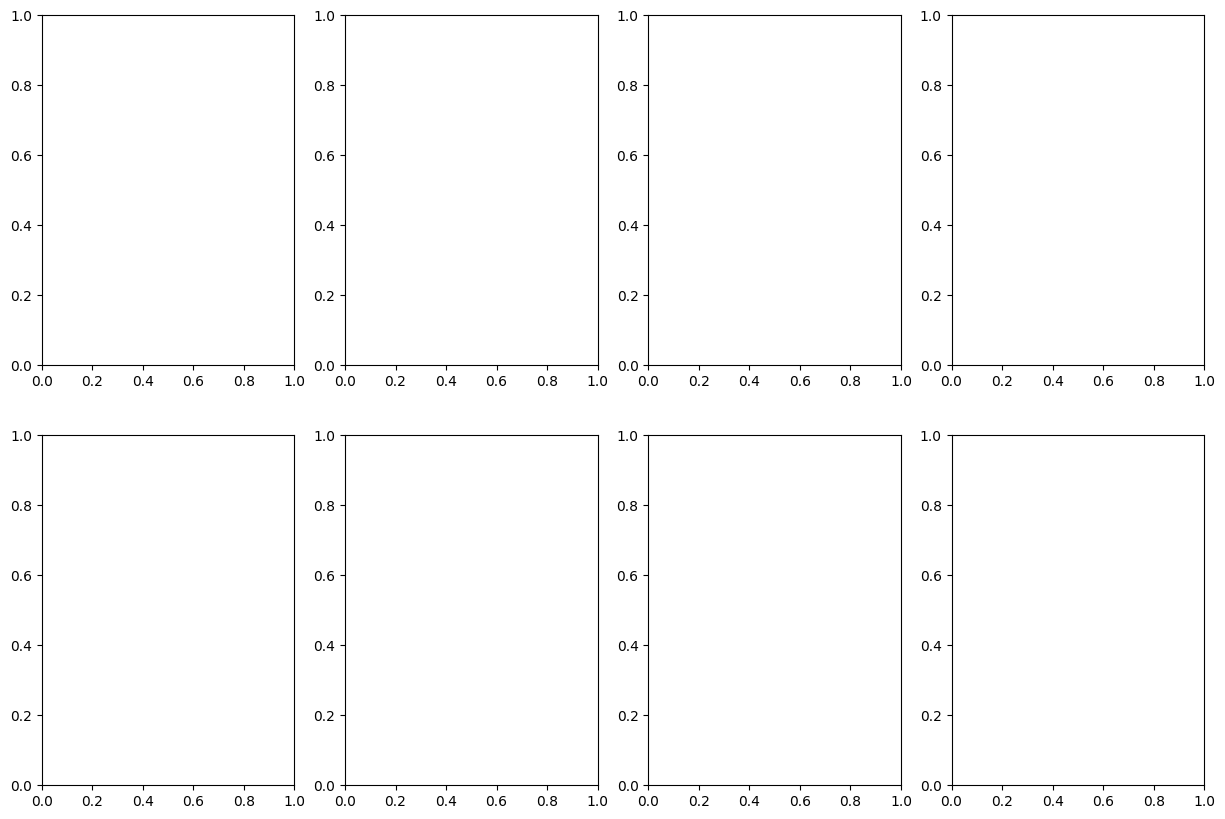

In [153]:
# Простой пример
analyzer = OpticalDataAnalyzer(n_components=4)

# Запуск с реальными длинами волн
factors = analyzer.fit_parafac(
    X=cleaned,
    excitation_wavelengths=ex_waves,
    emission_wavelengths=em_waves,
    sample_names=sp_names
)

# Визуализация
analyzer.plot_component_profiles()
analyzer.plot_concentration_profiles()
analyzer.print_component_summary()

loadings_table = analyzer.get_component_loadings(normalization='none')
print("Нормализованные нагрузки:")
print(loadings_table.head())

# 2. Таблица с процентными вкладами
percentage_table = analyzer.get_relative_contributions(method='percentage')
print("\nПроцентные вклады:")
print(percentage_table.head())

analyzer.plot_component_loadings(normalization='percentage')
fig2, ax2, eem2 = analyzer.plot_component_eem(component_idx=3, sample_idx=2)
plt.show()

In [133]:
loadings_table

,Component_1,Component_2,Component_3,Component_4
ADOM-SL1-1,1.449282,3.422870,1.424674,2.412591
ADOM-SL1-10,2.321487,5.544530,2.464933,3.644110
ADOM-SL1-3,1.726113,3.974341,0.592486,1.438899
ADOM-SL1-4,0.677580,2.125827,0.575179,0.879785
ADOM-SL1-5,0.177912,0.524257,0.190896,0.131455
...,...,...,...,...
ADOM-SLB-B3-1,0.410429,1.072461,0.247605,0.375047
ADOM-SLB-B3-2,1.059107,4.130506,0.934598,1.607660
ADOM-SLB-B3-3,0.304951,0.856544,0.249556,0.307546
ADOM-SLB-BO-2,0.277641,0.681624,0.145131,0.198017
